In [2]:
!pip install mne --break-system-packages

In [3]:
pip install --upgrade pip

  Using cached pip-26.1.2-py3-none-any.whl.metadata (4.6 kB)
Using cached pip-26.1.2-py3-none-any.whl (1.8 MB)
  Attempting uninstall: pip
    Found existing installation: pip 25.2
    Uninstalling pip-25.2:
      Successfully uninstalled pip-25.2
Note: you may need to restart the kernel to use updated packages.


In [4]:
!pip install pyedflib
!pip install scipy
!pip install pandas
!pip install numpy
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 7.6 MB/s  0:00:00m eta 0:00:01


In [31]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
import pyedflib
import os
import warnings
warnings.filterwarnings('ignore')

In [58]:
# function to extract eeg from an edf file
def extract_eeg_from_file(filename, channel_idx):
    """
    Load one channel of EEG from an EDF file.
    
    Parameters:
    - filename: name of .edf file (e.g., 'chb01_03.edf')
    - channel_idx: which channel to load (0-22 for 23 channels)
    
    Returns:
    - eeg_signal: numpy array of EEG samples
    
    Example:
    eeg_ch0 = extract_eeg_from_file('chb01_03.edf', 0)
    eeg_ch5 = extract_eeg_from_file('chb01_03.edf', 5)
    """

    # Combine the folder path with filename to create complete file path
    filepath = os.path.join(data_dir, filename)

    f = pyedflib.EdfReader(filepath)

    # Read the signal from one specific channel (0-22)
    eeg_signal = f.readSignal(channel_idx)
    
    f.close()
    
    return eeg_signal
    # will ultimately return a vector of eeg numbers (each number is the electrical voltage of the brain)
    

In [59]:
# define feature extraction functions
def calculate_entropy(signal_segment):
   
    
    # Create histogram of signal values (divide into 50 bins)
    # This shows the distribution of voltage values
    hist, _ = np.histogram(signal_segment, bins=50)
    
    # Normalize histogram to probability distribution (they should al sum to 1)
    # converting the counts into probabilities
    hist = hist / np.sum(hist)
    
    # Remove zero values
    # Keep only bins with actual data
    hist = hist[hist > 0]

    # use the entropy formula
    entropy_val = -np.sum(hist * np.log2(hist))

    return entropy_val
    

In [60]:
# line length extraction
def calculate_line_length(signal_segment):
    
    # Calculate difference between consecutive samples
    # np.diff subtracts each value from the next one
    # Example: [100, 102, 101] → [102-100=2, 101-102=-1] → [2, -1]
    # creates a numpy array
    differences = np.diff(signal_segment)
    
    # Take absolute value (we care about magnitude, not direction)
    # Negative differences (going down) count same as positive (going up)
    # Example: [2, -1] → [2, 1]
    absolute_differences = np.abs(differences)
    
    # Sum all the changes together
    line_length_val = np.sum(absolute_differences)
    
    return line_length_val

In [61]:
def calculate_high_freq_power(signal_segment, sfreq = 256):

    # Determines window size for power spectral density calculation
    nperseg = min(1024, len(signal_segment))

    # Calculate power spectral density using Welch's method
    f, pxx = signal.welch(signal_segment, sfreq, nperseg=nperseg)
    
    # Extract frequencies above 20 Hz
    high_freq_band = pxx[f >= 20]
    
    # Sum all the power in the high-frequency band
    high_freq_power = np.sum(high_freq_band)
    
    return high_freq_power

In [62]:
def extract_features(signal_segment, sfreq=256):
    # Extract all three features from one EEG segment at once.
    
    
    entropy_val = calculate_entropy(signal_segment)
    
    
    line_length_val = calculate_line_length(signal_segment)
    
    
    high_freq_val = calculate_high_freq_power(signal_segment, sfreq)
    
    
    return entropy_val, line_length_val, high_freq_val



In [63]:

def extract_features_sliding(eeg, sfreq, start_sec, end_sec, window_sec, step_sec):
    # Initialize lists to store results
    times = []
    entropies = []
    line_lengths = []
    high_freqs = []
    
    # Start at the beginning of the period
    current_time = start_sec

    while current_time + window_sec <= end_sec:
        # Convert seconds to sample indices (samples = seconds multiplied by th sampling_rate)
        start_idx = int(current_time * sfreq)
        end_idx = int((current_time + window_sec) * sfreq)

        # Extract the EEG signal for this window
        # seg = EEG data from start_idx to end_idx
        # collect the data from only that window
        
        seg = eeg[start_idx:end_idx]

        # Process if we have valid data
        if len(seg) > 0:
            
            # Extract all three features from this window
            e, ll, hf = extract_features(seg, sfreq)
            
            # Store measurements
            times.append(current_time - start_sec)
            entropies.append(e)
            line_lengths.append(ll)
            high_freqs.append(hf)
        
        # Move to the next measurement point
        current_time += step_sec
    
    # Return all of thw measurements
    return times, entropies, line_lengths, high_freqs

        

In [68]:
# All 7 seizures for chb01
seizures_all = [
    {'file': 'chb01_03.edf', 'start': 2996, 'end': 3036},
    {'file': 'chb01_04.edf', 'start': 1467, 'end': 1494},
    {'file': 'chb01_15.edf', 'start': 1732, 'end': 1772},
    {'file': 'chb01_16.edf', 'start': 1015, 'end': 1066},
    {'file': 'chb01_18.edf', 'start': 1720, 'end': 1810},
    {'file': 'chb01_21.edf', 'start': 327,  'end': 420},
    {'file': 'chb01_26.edf', 'start': 1862, 'end': 1963},
]

# Clean baseline files (no seizures, at least 1 hour from any seizure)
clean_files = [
    'chb01_07.edf',
    'chb01_08.edf',
    'chb01_09.edf',
    'chb01_10.edf',
    'chb01_11.edf',
    'chb01_12.edf',
    'chb01_13.edf',
]

# Setup
data_dir = '../data/chb01/'
sfreq = 256
n_channels = 23

print(f"Sampling frequency: {sfreq} Hz")
print(f"Number of channels: {n_channels}")
print(f"Total seizures: {len(seizures_all)}")
print(f"Clean baseline files: {len(clean_files)}")

# reparse summary files if kernel was restarted
if 'all_patients_seizures' not in dir():
    patient_ids = [f'chb{str(i).zfill(2)}' for i in range(1, 25) if i != 21]
    all_patients_seizures = {}
    for patient_id in patient_ids:
        seizures = parse_summary_file(patient_id)
        if len(seizures) > 0:
            all_patients_seizures[patient_id] = seizures
    print(f"✓ {len(all_patients_seizures)} patients reparsed")

Sampling frequency: 256 Hz
Number of channels: 23
Total seizures: 7
Clean baseline files: 7


In [69]:
# Cell 2: Random baseline selection from clean files

np.random.seed(1)  

BASELINE_DURATION = 120  # 2 minutes
max_start = 3600 - BASELINE_DURATION  # latest possible start = 3480s

baseline_windows = {}

for i, (seizure, clean_file) in enumerate(zip(seizures_all, clean_files)):
    random_start = np.random.randint(0, max_start)
    random_end = random_start + BASELINE_DURATION
    
    baseline_windows[i] = {
        'seizure_file': seizure['file'],
        'seizure_start': seizure['start'],
        'baseline_file': clean_file,
        'baseline_start': random_start,
        'baseline_end': random_end,
    }
    
    print(f"Seizure {i+1}: {seizure['file']} (onset {seizure['start']}s)")
    print(f"  Baseline: {clean_file} : {random_start}s → {random_end}s")
    print()



Seizure 1: chb01_03.edf (onset 2996s)
  Baseline: chb01_07.edf : 1061s → 1181s

Seizure 2: chb01_04.edf (onset 1467s)
  Baseline: chb01_08.edf : 235s → 355s

Seizure 3: chb01_15.edf (onset 1732s)
  Baseline: chb01_09.edf : 1096s → 1216s

Seizure 4: chb01_16.edf (onset 1015s)
  Baseline: chb01_10.edf : 905s → 1025s

Seizure 5: chb01_18.edf (onset 1720s)
  Baseline: chb01_11.edf : 2763s → 2883s

Seizure 6: chb01_21.edf (onset 327s)
  Baseline: chb01_12.edf : 2895s → 3015s

Seizure 7: chb01_26.edf (onset 1862s)
  Baseline: chb01_13.edf : 960s → 1080s



In [70]:
# Cell 3: Extract features for all 7 seizures with clean baselines

# Channel names from CHB-MIT summary file
channel_names = [
    'FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1',
    'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1',
    'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2',
    'FP2-F8', 'F8-T8', 'T8-P8', 'P8-O2',
    'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9',
    'FT9-FT10', 'FT10-T8', 'T8-P8'
]

all_seizure_results = {}

for sz_idx, seizure in enumerate(seizures_all):
    print(f"\nProcessing seizure {sz_idx+1}/7: {seizure['file']}")
    
    bw = baseline_windows[sz_idx]
    sz_start = seizure['start']
    
    preictal_start = sz_start - 120
    preictal_end   = sz_start
    
    print(f"  Baseline:  {bw['baseline_file']} {bw['baseline_start']}s -> {bw['baseline_end']}s")
    print(f"  Preictal:  {sz_start - 120}s → {sz_start}s")
    
    seizure_results = {}
    
    for ch in range(n_channels):
        # Load baseline from clean file
        try:
            eeg_baseline = extract_eeg_from_file(bw['baseline_file'], ch)
        except:
            print(f"  Channel {ch}: baseline load failed")
            continue
        
        # Load preictal from seizure file
        try:
            eeg_preictal = extract_eeg_from_file(seizure['file'], ch)
        except:
            print(f"  Channel {ch}: preictal load failed")
            continue
        
        # Extract baseline features
        t_b, e_b, ll_b, hf_b = extract_features_sliding(
            eeg_baseline, sfreq,
            bw['baseline_start'], bw['baseline_end'],
            window_sec=30, step_sec=30
        )
        
        # Extract preictal features
        t_p, e_p, ll_p, hf_p = extract_features_sliding(
            eeg_preictal, sfreq,
            preictal_start, preictal_end,
            window_sec=30, step_sec=30
        )
        
        # Average across windows
        entropy_baseline    = np.mean(e_b)
        ll_baseline         = np.mean(ll_b)
        hf_baseline         = np.mean(hf_b)
        
        entropy_preictal    = np.mean(e_p)
        ll_preictal         = np.mean(ll_p)
        hf_preictal         = np.mean(hf_p)
        
        # % change
        entropy_change = (entropy_preictal - entropy_baseline) / entropy_baseline * 100 if entropy_baseline != 0 else 0
        ll_change      = (ll_preictal - ll_baseline)           / ll_baseline      * 100 if ll_baseline != 0 else 0
        hf_change      = (hf_preictal - hf_baseline)           / hf_baseline      * 100 if hf_baseline != 0 else 0
        
        seizure_results[ch] = {
            'channel_name':         channel_names[ch],
            'entropy_change_%':     entropy_change,
            'line_length_change_%': ll_change,
            'hf_change_%':          hf_change,
            'entropy_values':       e_p,
            'll_values':            ll_p,
            'hf_values':            hf_p,
            'entropy_baseline_values': e_b,
            'll_baseline_values':   ll_b,
            'hf_baseline_values':   hf_b,
        }
    
    all_seizure_results[sz_idx] = seizure_results
    print(f"  {len(seizure_results)} channels processed")




Processing seizure 1/7: chb01_03.edf
  Baseline:  chb01_07.edf 1061s -> 1181s
  Preictal:  2876s → 2996s
  23 channels processed

Processing seizure 2/7: chb01_04.edf
  Baseline:  chb01_08.edf 235s -> 355s
  Preictal:  1347s → 1467s
  23 channels processed

Processing seizure 3/7: chb01_15.edf
  Baseline:  chb01_09.edf 1096s -> 1216s
  Preictal:  1612s → 1732s
  23 channels processed

Processing seizure 4/7: chb01_16.edf
  Baseline:  chb01_10.edf 905s -> 1025s
  Preictal:  895s → 1015s
  23 channels processed

Processing seizure 5/7: chb01_18.edf
  Baseline:  chb01_11.edf 2763s -> 2883s
  Preictal:  1600s → 1720s
  23 channels processed

Processing seizure 6/7: chb01_21.edf
  Baseline:  chb01_12.edf 2895s -> 3015s
  Preictal:  207s → 327s
  23 channels processed

Processing seizure 7/7: chb01_26.edf
  Baseline:  chb01_13.edf 960s -> 1080s
  Preictal:  1742s → 1862s
  23 channels processed


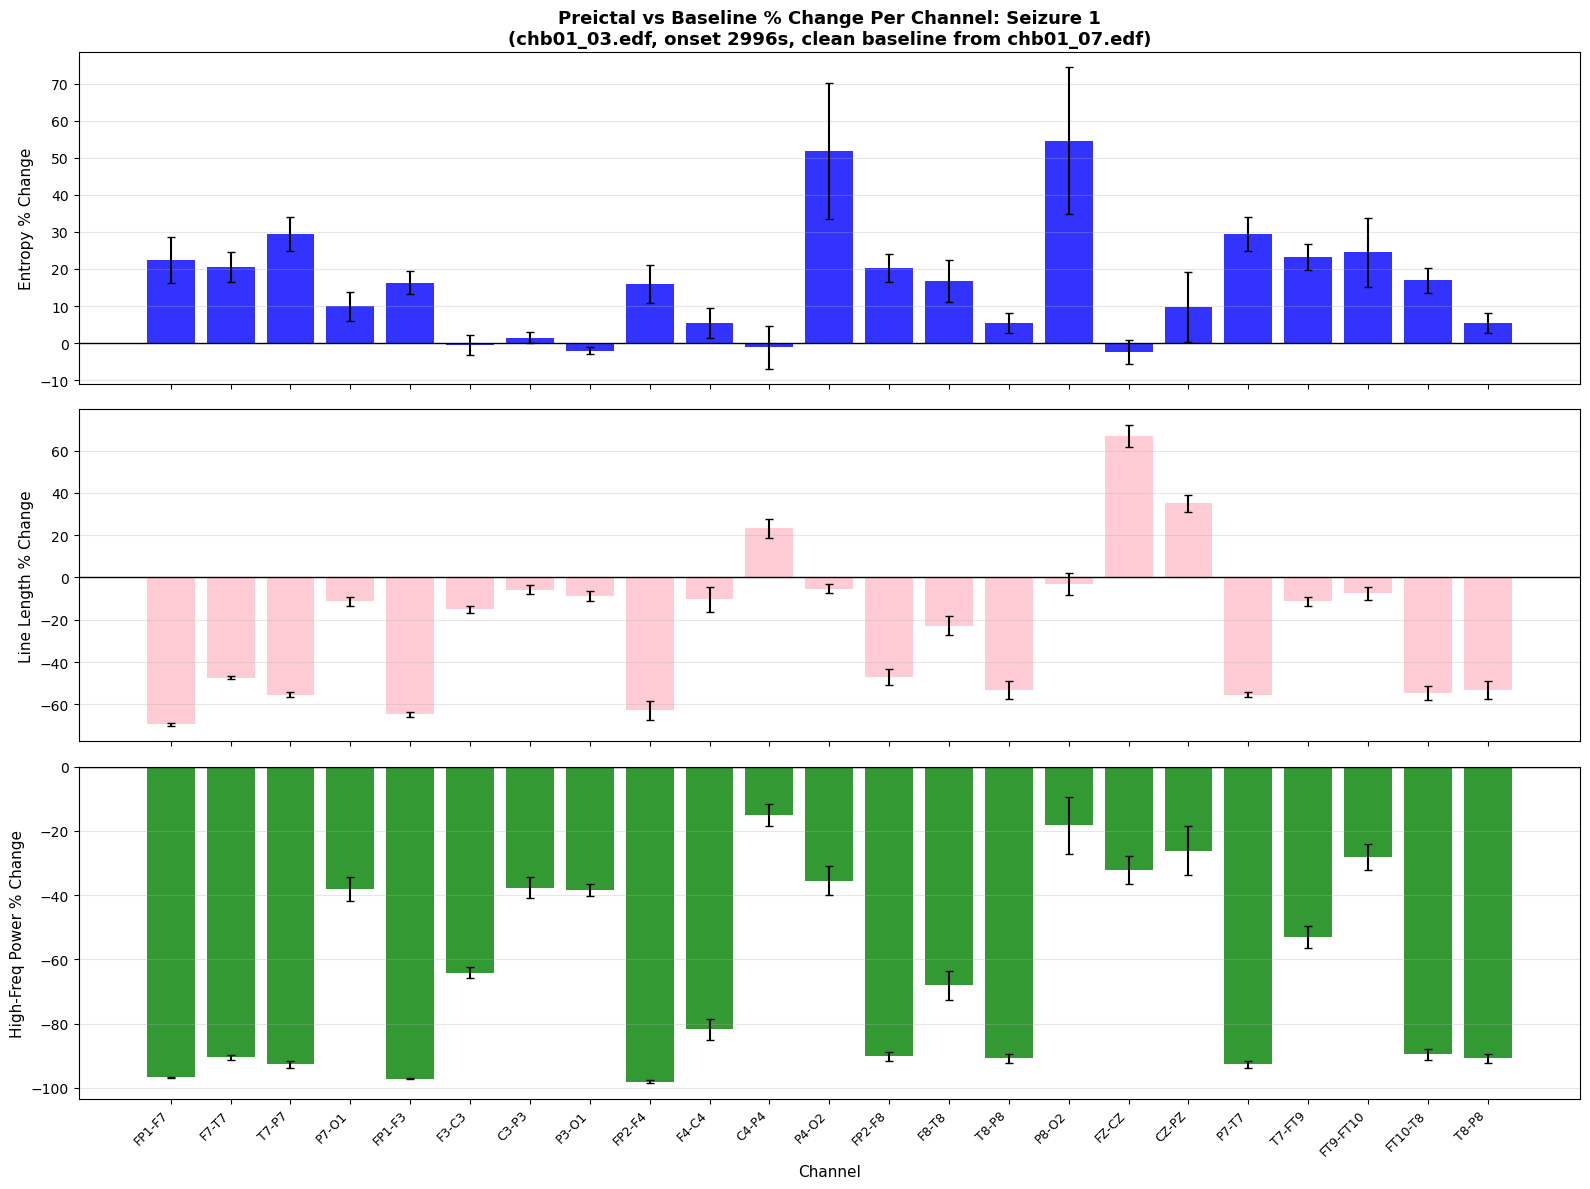

In [71]:
# Cell 4: Per-channel feature changes for seizure 1 with channel names and error bars

sz_idx = 0  # seizure 1
results = all_seizure_results[sz_idx]

channels = list(results.keys())
ch_names = [results[ch]['channel_name'] for ch in channels]

entropy_changes = [results[ch]['entropy_change_%'] for ch in channels]
ll_changes      = [results[ch]['line_length_change_%'] for ch in channels]
hf_changes      = [results[ch]['hf_change_%'] for ch in channels]
# Calculate SE of % change properly
# For each channel, calculate % change for each individual window pair
# then take SE across those % changes

entropy_se = []
ll_se = []
hf_se = []

for ch in channels:
    e_b = results[ch]['entropy_baseline_values']
    e_p = results[ch]['entropy_values']
    ll_b = results[ch]['ll_baseline_values']
    ll_p = results[ch]['ll_values']
    hf_b = results[ch]['hf_baseline_values']
    hf_p = results[ch]['hf_values']
    
    # % change per window
    e_changes  = [(p - b) / b * 100 for p, b in zip(e_p, e_b)]
    ll_changes_w = [(p - b) / b * 100 for p, b in zip(ll_p, ll_b)]
    hf_changes_w = [(p - b) / b * 100 for p, b in zip(hf_p, hf_b)]
    
    # SE = std / sqrt(n)
    entropy_se.append(np.std(e_changes) / np.sqrt(len(e_changes)))
    ll_se.append(np.std(ll_changes_w) / np.sqrt(len(ll_changes_w)))
    hf_se.append(np.std(hf_changes_w) / np.sqrt(len(hf_changes_w)))

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

features = [entropy_changes, ll_changes, hf_changes]
errors   = [entropy_se, ll_se, hf_se]
labels   = ['Entropy % Change', 'Line Length % Change', 'High-Freq Power % Change']
colors   = ['blue', 'pink', 'green']

x = np.arange(len(channels))

for ax, data, err, label, color in zip(axes, features, errors, labels, colors):
    ax.bar(x, data, color=color, alpha=0.8, yerr=err, capsize=3)
    ax.axhline(0, color='black', linewidth=1.0)
    ax.set_ylabel(label, fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')

axes[0].set_title('Preictal vs Baseline % Change Per Channel: Seizure 1\n(chb01_03.edf, onset 2996s, clean baseline from chb01_07.edf)',
                  fontsize=13, fontweight='bold')
axes[2].set_xlabel('Channel', fontsize=11)
axes[2].set_xticks(x)
axes[2].set_xticklabels(ch_names, rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.savefig('per_channel_clean_baseline_sz1.png', dpi=300, bbox_inches='tight')
plt.show()

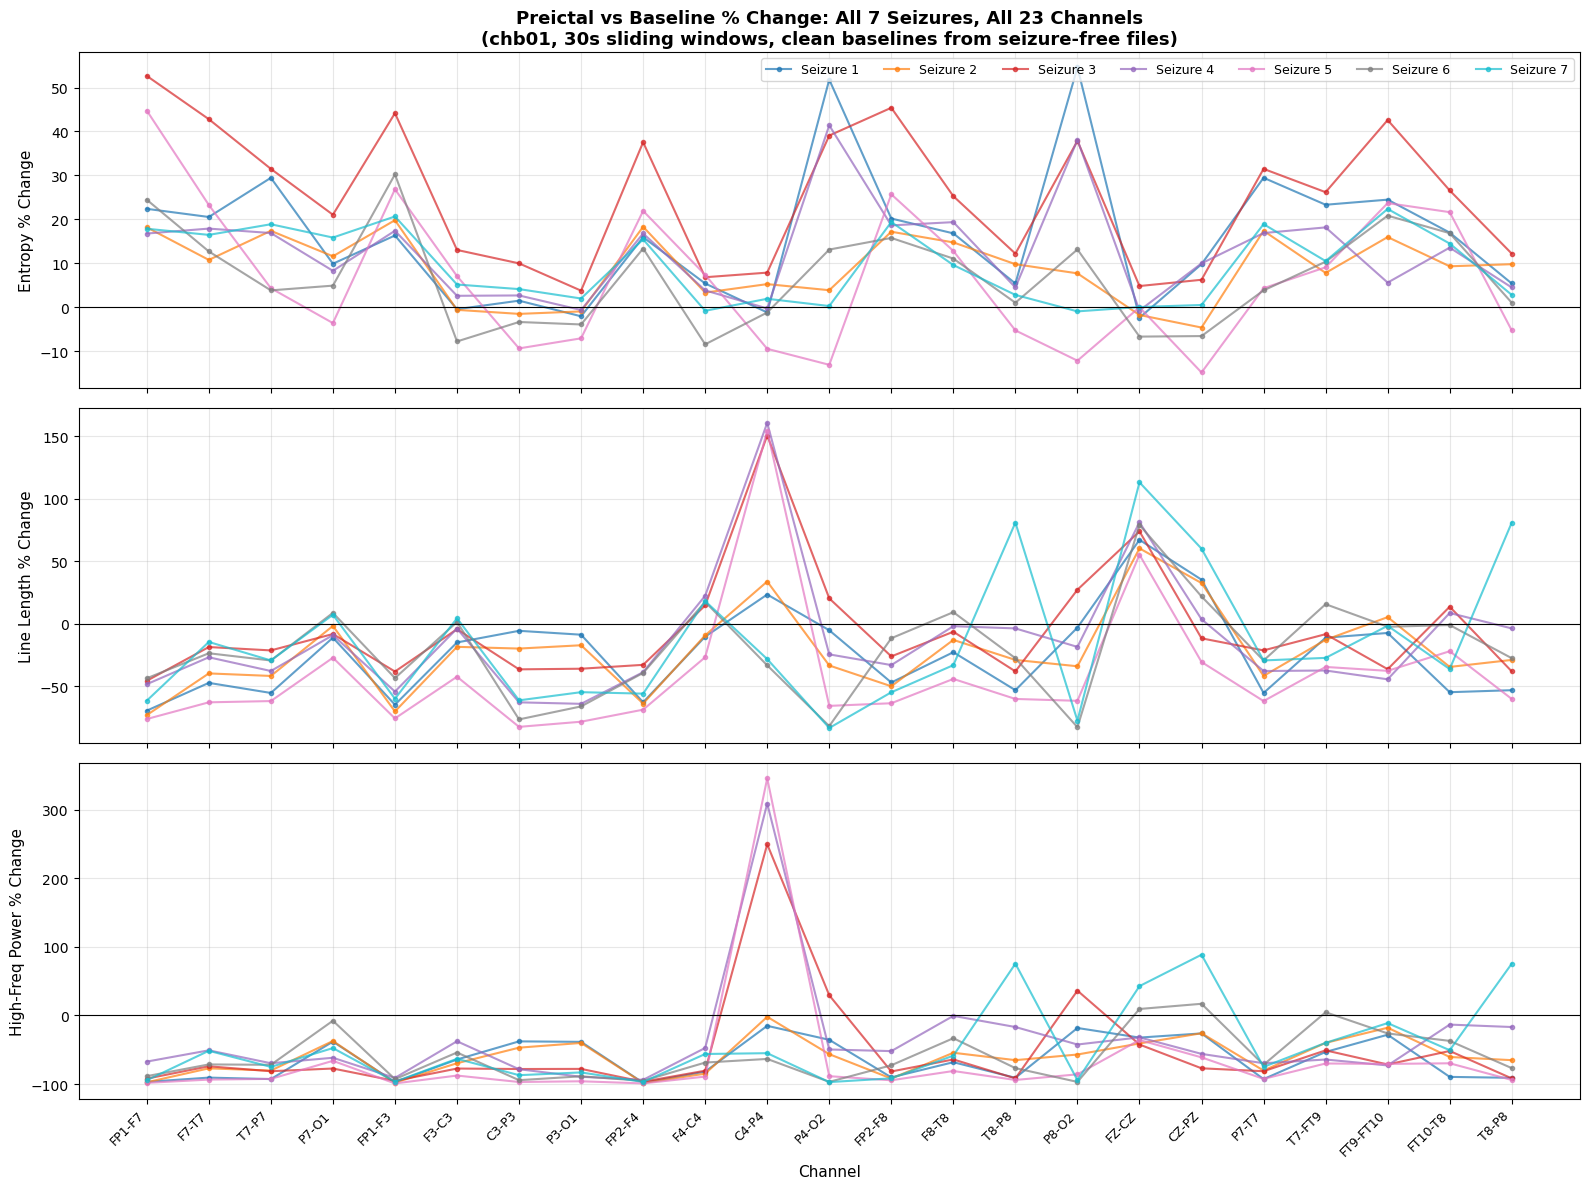

In [72]:
# Cell 5: All 7 seizures across all 23 channels with clean baselines

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

feature_keys   = ['entropy_change_%', 'line_length_change_%', 'hf_change_%']
feature_labels = ['Entropy % Change', 'Line Length % Change', 'High-Freq Power % Change']
colors = plt.cm.tab10(np.linspace(0, 0.9, 7))

for ax, fkey, flabel in zip(axes, feature_keys, feature_labels):
    for sz_idx in range(7):
        changes = [all_seizure_results[sz_idx][ch][fkey]
                   for ch in range(n_channels)
                   if ch in all_seizure_results[sz_idx]]
        
        ch_names_plot = [all_seizure_results[sz_idx][ch]['channel_name']
                         for ch in range(n_channels)
                         if ch in all_seizure_results[sz_idx]]
        
        ax.plot(range(len(changes)), changes,
                color=colors[sz_idx], alpha=0.7, linewidth=1.5,
                marker='o', markersize=3,
                label=f'Seizure {sz_idx+1}')

    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_ylabel(flabel, fontsize=11)
    ax.grid(True, alpha=0.3)

axes[0].set_title('Preictal vs Baseline % Change: All 7 Seizures, All 23 Channels\n(chb01, 30s sliding windows, clean baselines from seizure-free files)',
                  fontsize=13, fontweight='bold')
axes[0].legend(loc='upper right', fontsize=9, ncol=7)
axes[2].set_xlabel('Channel', fontsize=11)
axes[2].set_xticks(range(n_channels))
axes[2].set_xticklabels(ch_names_plot, rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.savefig('all_seizures_clean_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

In [73]:
import os

# check all files needed for temporal trend plot
files_needed = [
    'chb01_02.edf',  # for seizure 1
    'chb01_03.edf',  # for seizure 2
    'chb01_14.edf',  # for seizure 3
    'chb01_15.edf',  # for seizure 4
    'chb01_17.edf',  # for seizure 5
    'chb01_20.edf',  # for seizure 6
    'chb01_25.edf',  # for seizure 7
]

print("Checking required files:\n")
all_good = True
for f in files_needed:
    filepath = f'../data/chb01/{f}'
    if os.path.exists(filepath):
        size = os.path.getsize(filepath) / (1024 * 1024)
        print(f"✓ {f} — {size:.1f} MB")
    else:
        print(f"✗ {f} — NOT FOUND")
        all_good = False

if all_good:
    print("\n✓ All files present — ready to run temporal trend code")
else:
    print("\n✗ Some files missing — download before running")

Checking required files:

✓ chb01_02.edf — 40.4 MB
✓ chb01_03.edf — 40.4 MB
✓ chb01_14.edf — 40.4 MB
✓ chb01_15.edf — 40.4 MB
✓ chb01_17.edf — 40.4 MB
✓ chb01_20.edf — 29.9 MB
✓ chb01_25.edf — 40.4 MB

✓ All files present — ready to run temporal trend code


Computing full seizure cycle for all 7 seizures...

Seizure 1 (chb01_03.edf, onset 2996s, duration 40s)
  ✓ 69 time points extracted
Seizure 2 (chb01_04.edf, onset 1467s, duration 27s)
  ✓ 89 time points extracted
Seizure 3 (chb01_15.edf, onset 1732s, duration 40s)
  ✓ 89 time points extracted
Seizure 4 (chb01_16.edf, onset 1015s, duration 51s)
  ✓ 89 time points extracted
Seizure 5 (chb01_18.edf, onset 1720s, duration 90s)
  ✓ 90 time points extracted
Seizure 6 (chb01_21.edf, onset 327s, duration 93s)
  ✓ 80 time points extracted
Seizure 7 (chb01_26.edf, onset 1862s, duration 101s)
  ✓ 66 time points extracted

✓ All seizures processed


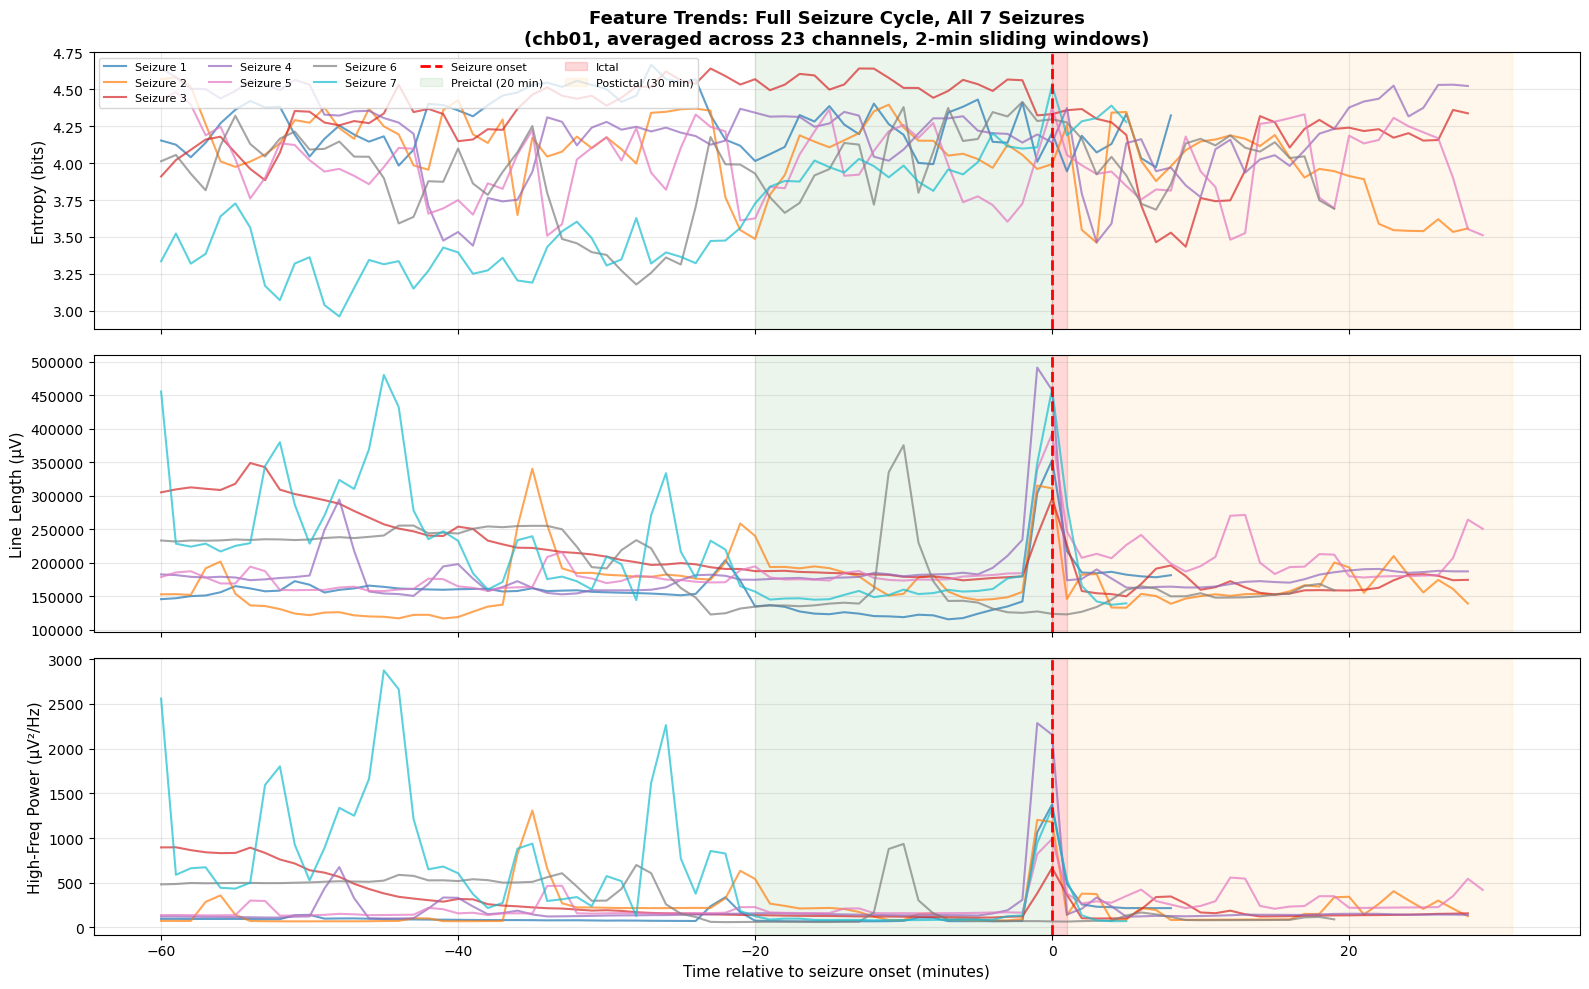

In [83]:
# Temporal Trend Plot — full seizure cycle for all 7 seizures of chb01

TREND_DURATION   = 3600  # 60 minutes before seizure
POSTICTAL_SEC    = 1800  # 30 minutes after seizure ends
TREND_WINDOW_SEC = 120   # 2-minute windows
TREND_STEP_SEC   = 60    # slide every 1 minute

# previous files for stitching
seizure_prev_files = {
    0: 'chb01_02.edf',  # seizure 1
    1: 'chb01_03.edf',  # seizure 2
    2: 'chb01_14.edf',  # seizure 3
    3: 'chb01_15.edf',  # seizure 4
    4: 'chb01_17.edf',  # seizure 5
    5: 'chb01_20.edf',  # seizure 6
    6: 'chb01_25.edf',  # seizure 7
}

all_trends = {}

print("Computing full seizure cycle for all 7 seizures...\n")

for sz_idx, sz in enumerate(seizures_all):
    sz_start    = sz['start']
    sz_end      = sz['end']
    sz_file     = sz['file']
    sz_duration = sz_end - sz_start
    prev_file   = seizure_prev_files[sz_idx]
    
    print(f"Seizure {sz_idx+1} ({sz_file}, onset {sz_start}s, duration {sz_duration}s)")
    
    need_from_prev = TREND_DURATION - sz_start
    
    # load and stitch channels
    stitched_channels = []
    for ch in range(n_channels):
        try:
            eeg_current = extract_eeg_from_file(sz_file, ch)
            postictal_end_sample = int((sz_end + POSTICTAL_SEC) * sfreq)
            eeg_current = eeg_current[:postictal_end_sample]
            
            if need_from_prev > 0:
                eeg_prev = extract_eeg_from_file(prev_file, ch)
                prev_samples = int(need_from_prev * sfreq)
                eeg_prev_section = eeg_prev[-prev_samples:]
                eeg_stitched = np.concatenate([eeg_prev_section, eeg_current])
            else:
                eeg_stitched = eeg_current
            
            stitched_channels.append(eeg_stitched)
        except:
            stitched_channels.append(None)
    
    # seizure onset position in stitched signal
    seizure_onset_in_signal = TREND_DURATION
    
    # extract features
    times_min   = []
    avg_entropy = []
    avg_ll      = []
    avg_hf      = []
    
    total_samples  = len([c for c in stitched_channels if c is not None][0])
    window_samples = int(TREND_WINDOW_SEC * sfreq)
    step_samples   = int(TREND_STEP_SEC   * sfreq)
    
    current_sample = 0
    while current_sample + window_samples <= total_samples:
        
        window_entropy = []
        window_ll      = []
        window_hf      = []
        
        for ch in range(n_channels):
            if stitched_channels[ch] is None:
                continue
            seg = stitched_channels[ch][current_sample:current_sample + window_samples]
            if len(seg) > 0:
                window_entropy.append(calculate_entropy(seg))
                window_ll.append(calculate_line_length(seg))
                window_hf.append(calculate_high_freq_power(seg, sfreq))
        
        time_min = (current_sample - seizure_onset_in_signal * sfreq) / sfreq / 60
        times_min.append(time_min)
        avg_entropy.append(np.mean(window_entropy))
        avg_ll.append(np.mean(window_ll))
        avg_hf.append(np.mean(window_hf))
        
        current_sample += step_samples
    
    all_trends[sz_idx] = {
        'times':       times_min,
        'entropy':     avg_entropy,
        'll':          avg_ll,
        'hf':          avg_hf,
        'sz_duration': sz_duration,
    }
    
    print(f"  ✓ {len(times_min)} time points extracted")

print("\n✓ All seizures processed")

# ── PLOT ─────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

feature_keys   = ['entropy', 'll', 'hf']
feature_labels = ['Entropy (bits)', 'Line Length (µV)', 'High-Freq Power (µV²/Hz)']
colors = plt.cm.tab10(np.linspace(0, 0.9, 7))

for ax, fkey, flabel in zip(axes, feature_keys, feature_labels):
    for sz_idx in range(7):
        if sz_idx not in all_trends:
            continue
        
        times = all_trends[sz_idx]['times']
        vals  = all_trends[sz_idx][fkey]
        sz_dur = all_trends[sz_idx]['sz_duration']
        
        ax.plot(times, vals,
                color=colors[sz_idx],
                alpha=0.7,
                linewidth=1.5,
                label=f'Seizure {sz_idx+1}')
    
    # mark seizure onset
    ax.axvline(0, color='red', linewidth=2,
               linestyle='--', label='Seizure onset')
    
    # shade regions
    ax.axvspan(-20, 0, alpha=0.08, color='green', label='Preictal (20 min)')
    ax.axvspan(0, 1, alpha=0.15, color='red', label='Ictal')
    ax.axvspan(1, 31, alpha=0.08, color='orange', label='Postictal (30 min)')
    
    ax.set_ylabel(flabel, fontsize=11)
    ax.grid(True, alpha=0.3)

axes[0].set_title(
    'Feature Trends: Full Seizure Cycle, All 7 Seizures\n'
    '(chb01, averaged across 23 channels, 2-min sliding windows)',
    fontsize=13, fontweight='bold'
)
axes[0].legend(loc='upper left', fontsize=8, ncol=5)
axes[2].set_xlabel('Time relative to seizure onset (minutes)', fontsize=11)

plt.tight_layout()
plt.savefig('temporal_trend_full_cycle_all_seizures.png', dpi=300, bbox_inches='tight')
plt.show()

Seizures with full postictal data: [1, 2, 3, 4, 5, 6]
Common time range: -60.0 to 8.0 minutes


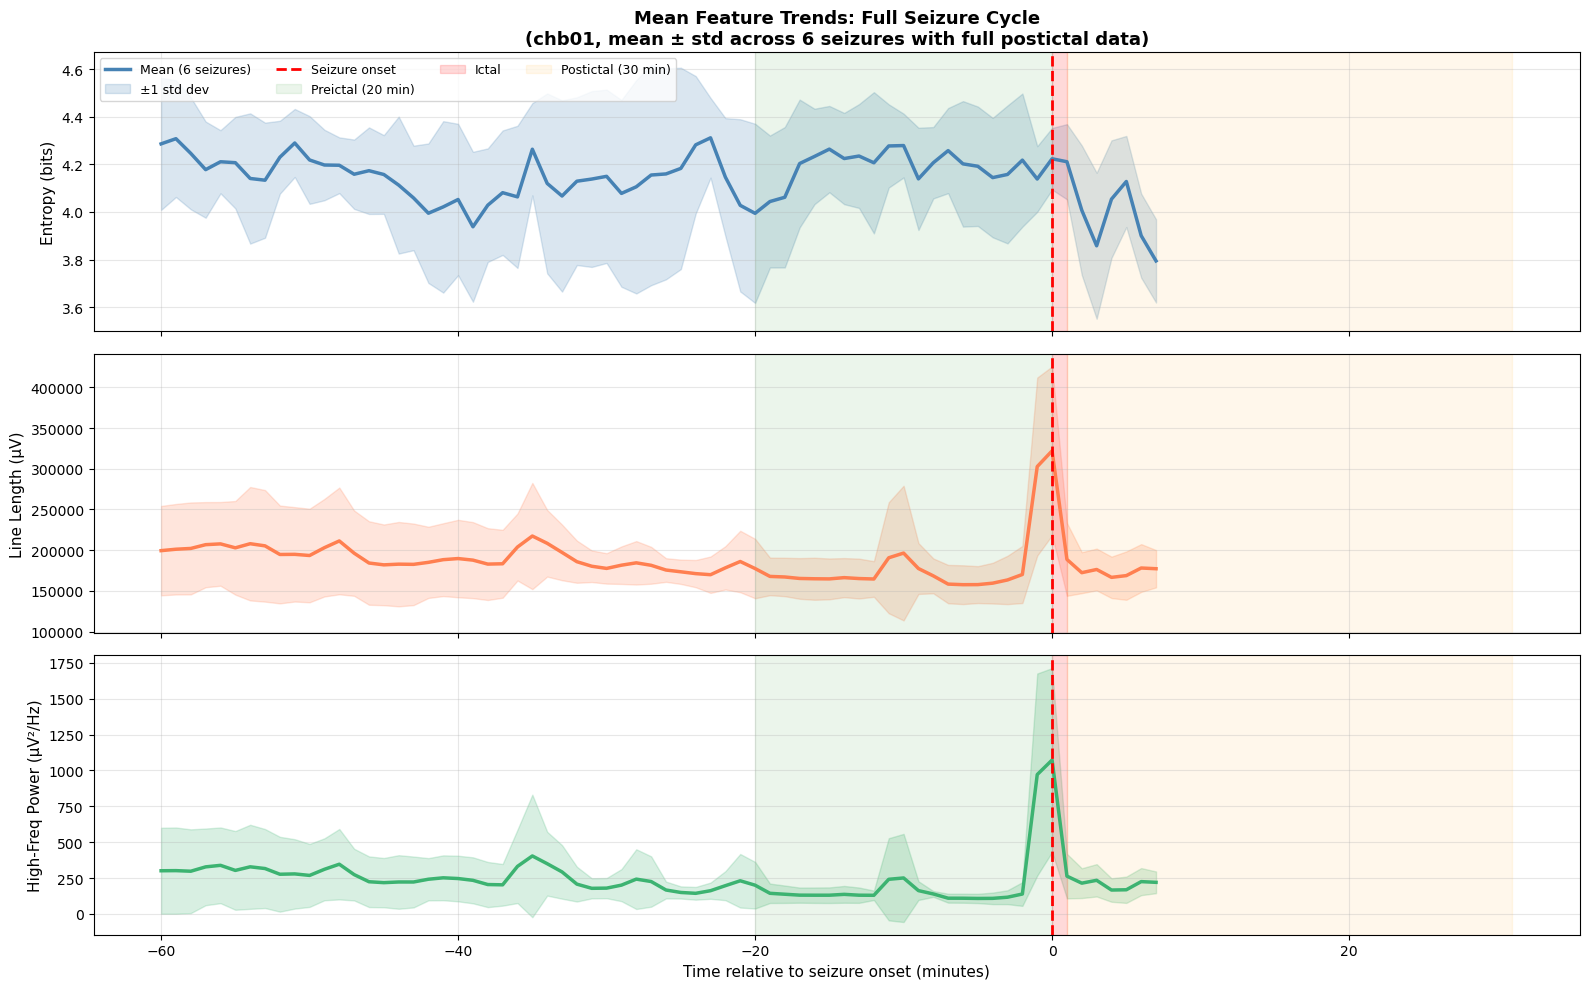

In [82]:
# find which seizures have full 30 min postictal
valid_postictal = []
for sz_idx in range(7):
    if sz_idx not in all_trends:
        continue
    max_t = max(all_trends[sz_idx]['times'])
    if max_t >= 5.5:  # at least 28 minutes postictal
        valid_postictal.append(sz_idx)

print(f"Seizures with full postictal data: {[i+1 for i in valid_postictal]}")

# find common time range for valid seizures only
min_time = max([min(all_trends[i]['times']) for i in valid_postictal])
max_time = min([max(all_trends[i]['times']) for i in valid_postictal])
ref_times = np.arange(min_time, max_time, TREND_STEP_SEC/60)

print(f"Common time range: {min_time:.1f} to {max_time:.1f} minutes")

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

feature_keys   = ['entropy', 'll', 'hf']
feature_labels = ['Entropy (bits)', 'Line Length (µV)', 'High-Freq Power (µV²/Hz)']
colors         = ['steelblue', 'coral', 'mediumseagreen']

for ax, fkey, flabel, color in zip(axes, feature_keys, feature_labels, colors):
    
    all_vals = []
    for sz_idx in valid_postictal:
        times = all_trends[sz_idx]['times']
        vals  = all_trends[sz_idx][fkey]
        vals_interp = np.interp(ref_times, times, vals)
        all_vals.append(vals_interp)
    
    all_vals  = np.array(all_vals)
    mean_vals = np.mean(all_vals, axis=0)
    std_vals  = np.std(all_vals, axis=0)
    
    ax.plot(ref_times, mean_vals, color=color,
            linewidth=2.5, label=f'Mean ({len(valid_postictal)} seizures)')
    ax.fill_between(ref_times,
                    mean_vals - std_vals,
                    mean_vals + std_vals,
                    color=color, alpha=0.2, label='±1 std dev')
    
    ax.axvline(0, color='red', linewidth=2, linestyle='--', label='Seizure onset')
    ax.axvspan(-20, 0,  alpha=0.08, color='green', label='Preictal (20 min)')
    ax.axvspan(0,   1,  alpha=0.15, color='red',   label='Ictal')
    ax.axvspan(1,   31, alpha=0.08, color='orange', label='Postictal (30 min)')
    ax.set_ylabel(flabel, fontsize=11)
    ax.grid(True, alpha=0.3)

axes[0].set_title(
    f'Mean Feature Trends: Full Seizure Cycle\n'
    f'(chb01, mean ± std across {len(valid_postictal)} seizures with full postictal data)',
    fontsize=13, fontweight='bold'
)
axes[0].legend(loc='upper left', fontsize=9, ncol=4)
axes[2].set_xlabel('Time relative to seizure onset (minutes)', fontsize=11)

plt.tight_layout()
plt.savefig('temporal_trend_mean_full_cycle.png', dpi=300, bbox_inches='tight')
plt.show()

In [67]:
print(data_dir)
import os
print(os.path.exists(os.path.join(data_dir, 'chb01_07.edf')))
print(os.path.exists(os.path.join(data_dir, 'chb01_03.edf')))

../data/
False
False


In [79]:
for i, bw in baseline_windows.items():
    print(f"Seizure {i+1}: {bw['baseline_file']} {bw['baseline_start']}s → {bw['baseline_end']}s")

Seizure 1: chb01_07.edf 1061s → 1181s
Seizure 2: chb01_08.edf 235s → 355s
Seizure 3: chb01_09.edf 1096s → 1216s
Seizure 4: chb01_10.edf 905s → 1025s
Seizure 5: chb01_11.edf 2763s → 2883s
Seizure 6: chb01_12.edf 2895s → 3015s
Seizure 7: chb01_13.edf 960s → 1080s
